## Demo: Gaussian Process of One Service (Image Denoiser)

This notebook shows the execution-time model of one service as a 3D surface, as a static figure in the style of the GP figure of
`notebooks/summersoc/2_analyze_notebook.ipynb`: the GP mean, a 95% band around it, and the measured training runs.

- **Service:** the image denoiser (`image-denoiser:v1`), the first service of the chain of B.2
  (denoiser → object detector → face detector → compressor, `EVIDENCE_CHAIN` in `pegasus/evaluation_setup.py`).
- **Training data:** `N_TRAIN` runs of the service alone, drawn under the first seed from its
  benchmark runs with one to four workers (`training_campaign=WORKER_TRAINING`, `benchmark/w1/` to `benchmark/w4/`),
  drawn as B.1 draws them for its services.
- **Model:** the load-aware GP of Pegasus (`load_aware` in `pegasus/data.py`, `train_run_statistics_models` in
  `pegasus/service_gp.py`). Its inputs per run are
  - $c$, the number of workers of the service (knob `parallelism`, 1 to 4),
  - the quality knobs of the service: for the denoiser only the data quality (knob `data_quality`, the side
    length of the input image, in pixels); the detectors also have a model size (knob `model_size`),
  - $\log_{10}\lambda$, with $\lambda$ the arrival rate at the service, in items/s.

  Its target is $\ln \bar Y$, with $\bar Y$ the mean execution time of one item over a run, in seconds. The GP is
  fitted on the logarithm because the effects of the knobs on a real service multiply, and on the logarithm they add.
- **Plot axes:** a *quality* axis (the data quality itself, or a score of data quality and model size for a service
  with both) and a *load* axis, a score of the workers $c$ and the idle share per worker $1 - \rho$ (section
  *Reduced axes*). The GP keeps all its inputs; only the plot is two-dimensional.

In [ ]:
data_source = "real"

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display
from scipy.stats import norm

from pegasus.evaluation_setup import *
from pegasus.figures import paper_style
from pegasus.data import load_aware
from pegasus.real_data import chain_path, feature_names
from pegasus.service_gp import train_run_statistics_models

globals().update(configure(data_source))

service = "denoiser"     # node of the chain of B.2 whose GP is shown ("denoiser", "detector", "faces" or "compressor")
s = seeds[0]             # the first seed of every experiment: it draws the training runs
experiment = evidence_options(s)["experiment"]   # the chain of B.2, the one that has the denoiser (the chain of B.1 does not)

# the data of the chain of B.2 as B.2 loads it (2_B2_evidence.ipynb), with N_TRAIN runs per service as B.1 draws them, and the
# inputs that the load-aware models see
data = load_chain_data("real", experiment=experiment, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s],
                       n_train=N_TRAIN, training_campaign=WORKER_TRAINING)
view = load_aware(data)
names = feature_names(experiment, WORKER_TRAINING)[service] + ["log10_rate"]   # the rate is the last column (x_train_load)
x_train = view.x_train[service]           # (runs, inputs)
y_mean = data.y_train[service]            # mean execution time per run (s)
y_spread = data.y_train_spread[service]   # standard deviation of single items per run (s)
print(f"{service} = {chain_path(experiment)[1][service]}: {len(y_mean)} training runs, inputs {names}")

### Fit

The same fit as Pegasus in B.1 (`fit_services` in `pegasus/evaluation.py`): a GP on $\ln \bar Y$ with a Matérn-5/2
kernel that has one length scale per input (inputs standardized), plus a white-noise term, which absorbs the scatter
between runs at the same inputs. A second GP of the same model predicts the per-item spread; the plot shows only the
first one. A long length scale means the GP considers that input nearly irrelevant; the table lists them in units of
the input's standard deviation over the training runs.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    model = train_run_statistics_models({service: x_train}, {service: y_mean}, {service: y_spread}, [service])[service]
kernel = model.center.gp.kernel_   # constant * Matern + white noise
print(kernel)
display(pd.DataFrame({"length scale (std. dev. of the input)": kernel.k1.k2.length_scale}, index=names))

1.85**2 * Matern(length_scale=[3.54, 3.86, 4.59], nu=2.5) + WhiteKernel(noise_level=0.00602)


,length scale (std. dev. of the input)
parallelism,3.540251
data_quality,3.858272
log10_rate,4.593517


### Reduced axes

A 3D figure has room for two inputs, the GP has more. Each plot axis therefore stands for a group of inputs:

- **Quality axis:** the quality knobs of the service. With one knob (the denoiser: data quality, the image side
  length in px) the axis is that knob itself. With two (the detectors: data quality and model size) the axis is a
  score of both, built as described below.
- **Load axis:** a score of the workers $c$ and the idle share per worker $1 - \rho$, where
  $\rho = \lambda \bar Y / c$ is the utilization per worker, the share of time a worker is busy (dimensionless;
  computed for every training run from its arrival rate $\lambda$ and its measured mean execution time $\bar Y$).
  - *Why $\rho$ and not $\lambda$:* the benchmarks controlled $\rho$. They set the arrival rate of each run to
    $\lambda = \rho\, c / \bar Y$ for a target $\rho$, so a fast configuration (a small image) got a high rate, and an
    axis built from $\lambda$ would also encode the quality.
  - *Why the idle share $1 - \rho$ and not $\rho$:* on most services of the testbed an item takes longer with more
    workers and also longer when the workers are mostly idle (low $\rho$). Along an axis on which both $c$ and $\rho$
    grow, the first slows the service down and the second speeds it up, and the two effects cancel. With $c$ and
    $1 - \rho$ both inputs slow the service down, so along the load axis their effects add up: a high load score means
    many workers that are mostly idle.

**How a score is built.** Both inputs are standardized over the training runs (minus their mean, divided by their
standard deviation), and the score is a principal component of the two. For two standardized inputs the two principal
components are always their sum and their difference, each with weight $1/\sqrt{2}$; the correlation $r$ of the inputs
only decides which of the two comes first, and the sum keeps the share $(1 + r)/2$ of their variance. A score uses the
sum, so that both inputs grow along the axis. The sum is the first component when $r > 0$; when $r$ is close to zero,
the order of the components is decided by noise, and any direction keeps about half of the variance (table below).

**Back to the GP's inputs.** A point on the plot maps back to the quality knobs, $c$ and $\rho$ (the inverse of the
standardization, with the dropped component at zero). The GP needs $\log_{10}\lambda$ instead of $\rho$:
$\lambda = \rho\, c / \bar Y$, where $\bar Y$ is the GP's own prediction at that $\lambda$, so $\lambda$ is found by
fixed-point iteration. The ranges of the axes cover all training runs. Where a score would take one of its inputs
beyond that input's training range (for example, fewer than one worker), that input stays at its bound and only the
other input changes along the axis. Points between the measured settings have fractional workers (and model sizes):
there the surface is the GP's interpolation.

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


class InputAxis:
    """A plot axis that is one input itself (columns: runs x 1); the interface of CombinedAxis."""

    def __init__(self, columns: np.ndarray):
        self.low, self.high = columns.min(axis=0), columns.max(axis=0)
        self.range = self.low[0], self.high[0]

    def score(self, columns: np.ndarray) -> np.ndarray:
        return columns[:, 0]

    def inputs(self, scores: np.ndarray) -> np.ndarray:
        return np.asarray(scores, dtype=float)[:, None]


class CombinedAxis:
    """One plot axis from two inputs (columns: runs x 2): the principal component of the standardized inputs in which
    both inputs grow (their sum, see the markdown above)."""

    def __init__(self, columns: np.ndarray):
        self.scaler = StandardScaler().fit(columns)
        standardized = self.scaler.transform(columns)
        pca = PCA(2).fit(standardized)
        # of the two components (sum and difference), the one whose weights have the same sign, oriented to be positive
        k = int(np.argmax(pca.components_[:, 0] * pca.components_[:, 1]))
        self.weights = pca.components_[k] * np.sign(pca.components_[k, 0])
        self.rank = k + 1                                       # 1 if the sum is the first principal component
        self.variance_share = pca.explained_variance_ratio_[k]
        self.correlation = np.corrcoef(standardized.T)[0, 1]
        scores = self.score(columns)
        self.range = scores.min(), scores.max()                 # the scores of all training runs
        self.low, self.high = columns.min(axis=0), columns.max(axis=0)

    def score(self, columns: np.ndarray) -> np.ndarray:
        return self.scaler.transform(columns) @ self.weights

    def inputs(self, scores: np.ndarray) -> np.ndarray:
        """The two inputs at the given scores, with the dropped component at zero; an input that would leave its
        training range stays at its bound."""
        return np.clip(self.scaler.inverse_transform(np.outer(scores, self.weights)), self.low, self.high)


KNOB_LABELS = {"data_quality": "data quality (px)", "model_size": "model size"}
w, r = names.index("parallelism"), names.index("log10_rate")
quality_columns = [k for k, name in enumerate(names) if name in KNOB_LABELS]   # data quality and, for a detector, the model size
rho_train = 10 ** x_train[:, r] * y_mean / x_train[:, w]   # utilization per worker of every training run, rho = lambda * Ybar / c
# the load axis uses the idle share 1 - rho, so that both of its inputs slow the service down (see the markdown above)
columns = {"quality": x_train[:, quality_columns], "load": np.column_stack([x_train[:, w], 1 - rho_train])}
labels = {"quality": tuple(KNOB_LABELS[names[k]] for k in quality_columns), "load": ("workers c", "idle share per worker 1 − ρ")}
axes = {name: (CombinedAxis if values.shape[1] == 2 else InputAxis)(values) for name, values in columns.items()}
display(pd.DataFrame({name: {"inputs": " + ".join(labels[name]), "weights": np.round(axis.weights, 3),
                             "correlation r of the inputs": round(axis.correlation, 2), "variance share kept": round(axis.variance_share, 2),
                             "rank of the component": axis.rank,
                             "correlation of the score with ln Ybar": round(np.corrcoef(axis.score(columns[name]), np.log(y_mean))[0, 1], 2)}
                      for name, axis in axes.items() if isinstance(axis, CombinedAxis)}))

,load
inputs,workers c + idle share per worker 1 − ρ
weights,"[0.707, 0.707]"
correlation r of the inputs,0.14
variance share kept,0.57
rank of the component,1
correlation of the score with ln Ybar,0.12


### Surface over the quality and load axes

The figure shows the mean execution time $\bar Y$ (z axis, in ms) of the service over the quality axis (x axis: the
data quality in px, or a dimensionless score for a service with two quality knobs) and the load score (y axis,
dimensionless; section *Reduced axes*; the table below the figure translates axis values back to the inputs):

- **colored surface:** the GP prediction $\exp(\mu)$, with $\mu$ the GP mean of $\ln \bar Y$;
- **grey surfaces:** $\exp(\mu \pm z_{0.975}\,\sigma)$, with $\sigma$ the predictive standard deviation of
  $\ln \bar Y$ for a new run and $z_{0.975}$ the standard normal 97.5% quantile, so 95% of new run means should lie
  between them if the GP is right. On the logarithm the band is symmetric; on the time axis it is wider above the mean.
- **red points:** all training runs, at their own axis values. A score drops the second component of its pair, so a
  run lies off the surface also by that dropped part, not only by measurement noise.

What to look at: the rise of the surface along the load axis, from one busy worker (low score) to four mostly idle
workers (high score), next to its rise along the quality axis.

The figure is saved as PDF and JPG to `figures/tsc/gp_demo/` (path printed below the figure).

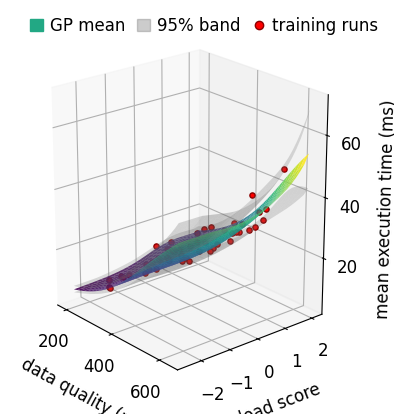

quality                         load            \
  axis value data quality (px) axis value workers c   
0      192.0             192.0      -2.48      1.00   
1      304.0             304.0      -1.35      1.31   
2      416.0             416.0      -0.21      2.24   
3      528.0             528.0       0.92      3.18   
4      640.0             640.0       2.06      4.00   

                               
  idle share per worker 1 − ρ  
0                        0.14  
1                        0.32  
2                        0.50  
3                        0.69  
4                        0.87

The arrival rates converged after 22 iterations; across the surface λ ranges from 9.6 to 133.3 items/s (training runs: 2.5 to 229.9 items/s). All 50 training runs are drawn; view azimuth -40.3°; the vertical axis of the box is stretched 1.64× so that the figure is 0.91 times as wide as high, like a half-width evaluation figure (0.91). Saved to `figures/tsc/gp_demo/transformer_gp_quality_load.pdf` and `.jpg`.

In [4]:
from itertools import product

from matplotlib.transforms import Bbox
from mpl_toolkits.mplot3d import proj3d
from scipy.optimize import brentq

from pegasus.figures import FIGSIZE

n_grid = 30
quality_axis, load_axis = axes["quality"], axes["load"]
grid_x, grid_y = np.meshgrid(np.linspace(*quality_axis.range, n_grid), np.linspace(*load_axis.range, n_grid))
x_grid = np.empty((n_grid * n_grid, len(names)))
x_grid[:, quality_columns] = quality_axis.inputs(grid_x.ravel())
x_grid[:, w], idle_grid = load_axis.inputs(grid_y.ravel()).T
rho_grid = 1 - idle_grid


def predicted_log_ybar(log_rate: np.ndarray) -> np.ndarray:
    x_grid[:, r] = log_rate
    return model.center.predict(x_grid)


# arrival rate of every grid point: lambda = rho * c / Ybar, with Ybar the GP's prediction at that lambda (fixed point),
# started at the median training rate
log_rate = np.full(len(x_grid), np.median(x_train[:, r]))
for iteration in range(100):
    updated = np.log10(rho_grid * x_grid[:, w]) - predicted_log_ybar(log_rate) / np.log(10)
    change, log_rate = np.abs(updated - log_rate).max(), updated
    if change < 1e-8:
        break
assert change < 1e-8, f"the arrival rates did not converge (largest change {change:.2g})"
x_grid[:, r] = log_rate
mu, sigma = model.center.predict(x_grid, return_std=True)
z = norm.ppf(0.975)
to_ms = lambda log_seconds: 1e3 * np.exp(log_seconds).reshape(grid_x.shape)
mean, upper, lower = to_ms(mu), to_ms(mu + z * sigma), to_ms(mu - z * sigma)

# proportions (width / height) of the saved figure: those of a half-width evaluation figure (FIGSIZE[0] / 2 wide, FIGSIZE[1]
# high, fraction_figure(0.5) in pegasus/figures.py), so that the two line up at the same height side by side in the paper
target_ratio = FIGSIZE[0] / 2 / FIGSIZE[1]

with paper_style():
    # taller than wide, so that the box, stretched vertically below, keeps its size within the canvas
    fig = plt.figure(figsize=(4.5, 5.0))
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(grid_x, grid_y, mean, cmap="viridis", alpha=0.9, linewidth=0)
    for band in (upper, lower):
        ax.plot_surface(grid_x, grid_y, band, color="grey", alpha=0.25, linewidth=0)
    ax.scatter(quality_axis.score(columns["quality"]), load_axis.score(columns["load"]), 1e3 * y_mean, color="red", edgecolor="darkred", s=14,
               depthshade=False)
    ax.set_xlabel(labels["quality"][0] if isinstance(quality_axis, InputAxis) else "quality score", labelpad=8)
    if isinstance(quality_axis, InputAxis):
        ax.xaxis.set_major_locator(MaxNLocator(3))   # at most three round ticks, so that the labels in px do not overlap
    ax.set_ylabel("load score", labelpad=8)
    ax.set_zlabel("mean execution time (ms)", labelpad=8)
    renderer, to_figure = fig.canvas.get_renderer(), fig.transFigure.inverted()
    labels_3d = [ax.xaxis.label, ax.yaxis.label, ax.zaxis.label]   # the tight crop does not count these by itself
    project = lambda corner: ax.transData.transform(proj3d.proj_transform(*corner, ax.get_proj())[:2])   # data -> display coordinates

    def plot_box() -> Bbox:
        # what the saved crop holds without the legend: the drawn axes and the axis labels, in display coordinates
        fig.canvas.draw()
        return Bbox.union([fig.get_tightbbox(renderer).transformed(fig.dpi_scale_trans)] + [label.get_window_extent(renderer) for label in labels_3d])

    def front_edge_share(azimuth: float) -> float:
        # horizontal position of the front edge of the box (where the quality and the load axis meet) in the crop, 0 to 1
        ax.view_init(elev=22, azim=azimuth)
        box = plot_box()
        return (project((ax.get_xlim()[1], ax.get_ylim()[0], ax.get_zlim()[0]))[0] - box.x0) / box.width

    def layout(stretch: float) -> float:
        """Draws the box with its vertical axis `stretch` times the default height (box aspect 4:4:3 of matplotlib), turns
        it to the chosen view and places the legend; returns the width / height of the saved crop."""
        global azimuth
        # full size: the crop counts the axis labels, so a label that reaches beyond the figure is kept, not cut off
        ax.set_box_aspect((4, 4, 3 * stretch), zoom=1.0)
        # the azimuth that puts the front edge in the horizontal middle of the crop (near the symmetric -45, shifted because
        # the z label widens the crop on the right), turned further left by `extra_rotation` degrees for the chosen view
        azimuth = brentq(lambda a: front_edge_share(a) - 0.5, -75, -20, xtol=0.05) + extra_rotation
        front_edge_share(azimuth)
        # one-row legend directly above the highest corner of the box (the 3D axes leave empty space above the box), centered
        # on the crop; short handles and spacing, because the legend is the widest part of the crop and a wider crop needs a
        # taller box to reach target_ratio
        box = plot_box()
        box_top = to_figure.transform((0, max(project(corner)[1] for corner in product(ax.get_xlim(), ax.get_ylim(), ax.get_zlim()))))[1]
        plot_middle = to_figure.transform(((box.x0 + box.x1) / 2, 0))[0]
        for legend in list(fig.legends):
            legend.remove()
        # surfaces have no legend entry of their own in a 3D axis, so proxies stand for them
        fig.legend(handles=[Patch(color=plt.get_cmap("viridis")(0.6), label="GP mean"), Patch(color="grey", alpha=0.4, label="95% band"),
                            Line2D([], [], marker="o", color="red", markeredgecolor="darkred", linestyle="", label="training runs")],
                   loc="lower center", bbox_to_anchor=(plot_middle, box_top), ncol=3, frameon=False, handlelength=0.8, handletextpad=0.4,
                   columnspacing=0.7)
        fig.canvas.draw()
        crop_box = fig.get_tightbbox(renderer, bbox_extra_artists=[*labels_3d, *fig.legends])
        return crop_box.width / crop_box.height

    extra_rotation = 10.0
    # the vertical stretch of the box that gives the saved crop the proportions of a half-width evaluation figure
    stretch = brentq(lambda k: layout(k) - target_ratio, 1.0, 3.0, xtol=0.01)
    crop_ratio = layout(stretch)
    out = Path("../../figures/tsc/gp_demo")
    out.mkdir(parents=True, exist_ok=True)
    name = f"{service}_gp_quality_load"
    crop = [*labels_3d, *fig.legends]
    fig.savefig(out / f"{name}.pdf", bbox_inches="tight", bbox_extra_artists=crop, pad_inches=0.02)
    fig.savefig(out / f"{name}.jpg", dpi=300, facecolor="white", bbox_inches="tight", bbox_extra_artists=crop, pad_inches=0.02)
    plt.show()

# what the axes mean: the inputs at five evenly spaced values of each axis
ticks = {name: np.linspace(*axis.range, 5) for name, axis in axes.items()}
display(pd.concat({name: pd.DataFrame(np.column_stack([ticks[name], axes[name].inputs(ticks[name])]), columns=("axis value", *labels[name])).round(2)
                   for name in axes}, axis=1))
rates = 10 ** log_rate
display(Markdown(f"The arrival rates converged after {iteration + 1} iterations; across the surface λ ranges from {rates.min():.1f} to "
                 f"{rates.max():.1f} items/s (training runs: {10 ** x_train[:, r].min():.1f} to {10 ** x_train[:, r].max():.1f} items/s). "
                 f"All {len(y_mean)} training runs are drawn; view azimuth {azimuth:.1f}°; the vertical axis of the box is stretched "
                 f"{stretch:.2f}× so that the figure is {crop_ratio:.2f} times as wide as high, like a half-width evaluation figure "
                 f"({target_ratio:.2f}). Saved to `figures/tsc/gp_demo/{name}.pdf` and `.jpg`."))